# Análisis exploratorio del dataset PCam

La competición [TNM112-Lab2 (2026)](https://www.kaggle.com/competitions/tnm-112-lab-2-2026) utiliza fragmentos de imágenes histopatológicas para una clasificación binaria. En este cuaderno se revisan los archivos proporcionados por la competición, su estructura y la distribución de sus etiquetas. También se muestran ejemplos de las imágenes. Cada fragmento tiene 32 × 32 píxeles y tres canales de color.

El análisis comprende los conjuntos de entrenamiento, validación y prueba. Los resultados se guardaron en el cuaderno para que puedan consultarse directamente en GitHub.

## 1. Acceso a los datos

Los archivos se descargan desde la [página de datos de Kaggle](https://www.kaggle.com/competitions/tnm-112-lab-2-2026/data). Para ejecutar el cuaderno en Google Colab:

1. Descargar y descomprimir los archivos `train.h5`, `valid.h5` y `test_x.h5`.
2. Crear la carpeta `Challenge3/data` dentro de Mi unidad de Google Drive y colocar allí los tres archivos.
3. Abrir este cuaderno en Colab con el enlace disponible en el repositorio. En **Entorno de ejecución**, seleccionar **Ejecutar todas**.
4. Autorizar el acceso a Google Drive cuando Colab lo solicite. La ruta de datos puede modificarse en la siguiente celda si se usó otra carpeta.

En Jupyter local, los archivos pueden colocarse en la carpeta `data/` del repositorio. La variable `DATOS` debe apuntar a esa ubicación.

In [1]:
from pathlib import Path
import os
import sys

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    DATOS = Path("/content/drive/MyDrive/Challenge3/data")
else:
    # En Jupyter local, esta ruta supone que el cuaderno se abre desde notebooks/.
    DATOS = Path(os.environ.get("CHALLENGE3_DATOS", "../data"))

archivos = ["train.h5", "valid.h5", "test_x.h5"]
faltantes = [nombre for nombre in archivos if not (DATOS / nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos en la carpeta de datos: " + ", ".join(faltantes))
print("Los tres archivos están disponibles.")

Los tres archivos están disponibles.


## 2. Estructura de los archivos

Los datos están en formato HDF5 (`.h5`). La clave `x` contiene las imágenes y, cuando está disponible, la clave `y` contiene la etiqueta de cada imagen. Para no cargar todas las imágenes a la vez, el rango de píxeles se calcula por lotes.

In [2]:
resumen = []
conteos = []
ejemplos = {}

for nombre in archivos:
    with h5py.File(DATOS / nombre, "r") as archivo:
        imagenes = archivo["x"]
        minimo, maximo = 255, 0
        for inicio in range(0, len(imagenes), 2048):
            lote = imagenes[inicio:inicio + 2048]
            minimo = min(minimo, int(lote.min()))
            maximo = max(maximo, int(lote.max()))
        resumen.append({
            "Archivo": nombre,
            "Claves": ", ".join(archivo.keys()),
            "Imágenes (x)": str(imagenes.shape),
            "Tipo de x": str(imagenes.dtype),
            "Etiquetas (y)": str(archivo["y"].shape) if "y" in archivo else "No disponibles",
            "Tipo de y": str(archivo["y"].dtype) if "y" in archivo else "No disponibles",
            "Píxeles": f"{minimo}–{maximo}"
        })
        if "y" in archivo:
            etiquetas = archivo["y"][:].reshape(-1)
            if len(etiquetas) != len(imagenes):
                raise ValueError(f"Las imágenes y etiquetas no coinciden en {nombre}.")
            clases, cantidades = np.unique(etiquetas, return_counts=True)
            for clase, cantidad in zip(clases, cantidades):
                conteos.append({"Archivo": nombre, "Clase": int(clase),
                                 "Cantidad": int(cantidad),
                                 "Porcentaje": 100 * int(cantidad) / len(etiquetas)})
            for clase in (0, 1):
                indices = np.flatnonzero(etiquetas == clase)[:4]
                ejemplos[(nombre, clase)] = [(int(i), imagenes[int(i)]) for i in indices]

display(pd.DataFrame(resumen))

,Archivo,Claves,Imágenes (x),Tipo de x,Etiquetas (y),Tipo de y,Píxeles
0,train.h5,"x, y","(100000, 32, 32, 3)",uint8,"(100000,)",uint8,0–255
1,valid.h5,"x, y","(32768, 32, 32, 3)",uint8,"(32768,)",uint8,0–255
2,test_x.h5,x,"(32768, 32, 32, 3)",uint8,No disponibles,No disponibles,0–255


En `train.h5` y `valid.h5` se encontraron imágenes y etiquetas. El archivo `test_x.h5` contiene imágenes, pero no etiquetas ni identificadores. La correspondencia entre el orden de prueba y los ID de la submission queda pendiente de verificación.

## 3. Distribución de clases

La clase 0 representa la etiqueta negativa y la clase 1, la positiva. Las proporciones se calcularon con todas las etiquetas disponibles en entrenamiento y validación.

,Archivo,Clase,Cantidad,Porcentaje
0,train.h5,0,49964,49.964
1,train.h5,1,50036,50.036
2,valid.h5,0,16399,50.046
3,valid.h5,1,16369,49.954


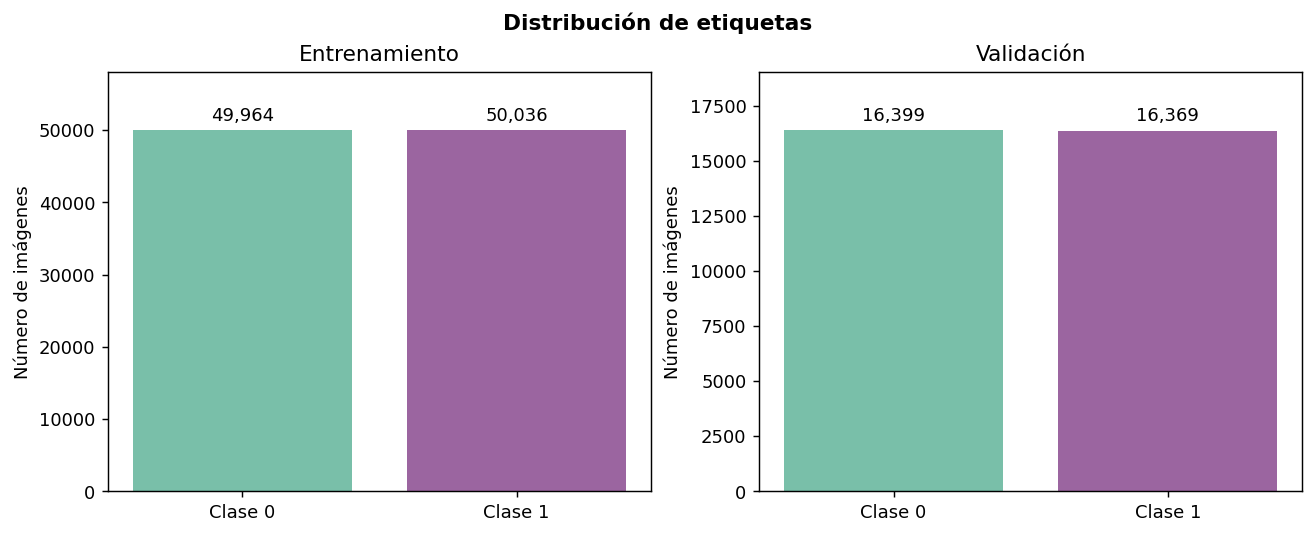

In [3]:
tabla_clases = pd.DataFrame(conteos)
display(tabla_clases.round({"Porcentaje": 3}))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for eje, nombre, titulo in zip(ejes, ["train.h5", "valid.h5"], ["Entrenamiento", "Validación"]):
    datos = tabla_clases[tabla_clases["Archivo"] == nombre].sort_values("Clase")
    barras = eje.bar(["Clase 0", "Clase 1"], datos["Cantidad"], color=["#79bfa9", "#9b65a0"])
    eje.bar_label(barras, labels=[f"{n:,}" for n in datos["Cantidad"]], padding=3)
    eje.set_title(titulo)
    eje.set_ylabel("Número de imágenes")
    eje.set_ylim(0, datos["Cantidad"].max() * 1.16)
fig.suptitle("Distribución de etiquetas", fontweight="bold")
plt.show()

Las dos clases presentan cantidades similares en ambos conjuntos. El archivo de prueba no dispone de etiquetas, por lo que su distribución de clases no puede calcularse con estos datos.

## 4. Ejemplos de imágenes

Se muestran los primeros cuatro ejemplos de cada clase encontrados en entrenamiento y validación. Su selección permite observar el formato de los datos; no representa toda la variabilidad del conjunto.

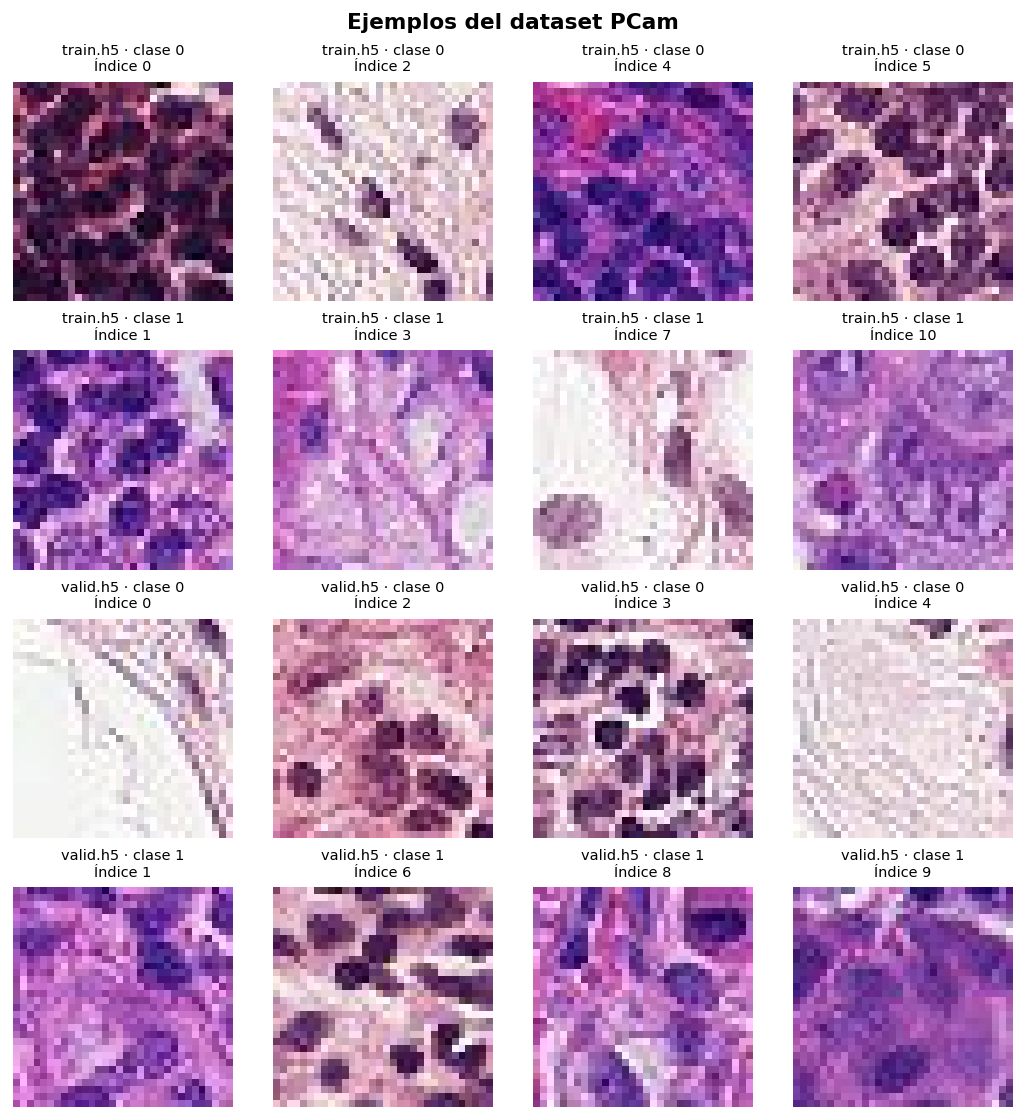

In [4]:
fig, ejes = plt.subplots(4, 4, figsize=(8, 8.5), constrained_layout=True)
for fila, (nombre, clase) in enumerate([( "train.h5", 0), ("train.h5", 1),
                                         ("valid.h5", 0), ("valid.h5", 1)]):
    for columna, (indice, imagen) in enumerate(ejemplos[(nombre, clase)]):
        eje = ejes[fila, columna]
        eje.imshow(imagen, interpolation="nearest")
        eje.set_title(f"{nombre} · clase {clase}\nÍndice {indice}", fontsize=8)
        eje.axis("off")
fig.suptitle("Ejemplos del dataset PCam", fontweight="bold")
plt.show()

## 5. Preparación para el modelo

Cada imagen tiene tres canales y valores entre 0 y 255. Una preparación posible consiste en convertir los píxeles a valores decimales y dividirlos entre 255. La misma transformación debe aplicarse a los tres conjuntos.

Entrenamiento se utiliza para ajustar el modelo, validación para evaluar su desarrollo y prueba para generar las predicciones solicitadas. Cualquier parámetro aprendido durante el preprocesamiento debe calcularse solo con entrenamiento.

**Fuentes:** [competición en Kaggle](https://www.kaggle.com/competitions/tnm-112-lab-2-2026/data) y [PatchCamelyon](https://github.com/basveeling/pcam).